In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os, glob, json
import pandas as pd

P2 = os.path.dirname(glob.glob("/kaggle/input/**/final_holdout_summary.json", recursive=True)[0])
OUT = "/kaggle/working/final_tables"; os.makedirs(OUT, exist_ok=True)
print("phase2 folder:", P2)

# --- DEV subset (02-scoring-and-merging; JSON 30 / SQL 60 / SAMSum 50 rows, Tone loss 150) ---
# GR = (merged - base) / (solo - base); tone loss: (base - merged) / (base - solo)
DEV = [
 # method,               family,                    setting,          json,  sql,  samsum, tone, sql_em, svd_err
 ("M1  λ=1.0",          "Weighted (concat)",       "λ=1.0",          0.13, 0.93, 0.64, 1.19, 0.050, 0.0),
 ("M1  λ=0.5",          "Weighted (concat)",       "λ=0.5",          0.99, 0.87, 0.83, 1.22, 0.017, 0.0),
 ("M1  λ=0.25",         "Weighted (concat)",       "λ=0.25",         0.96, 0.85, 0.64, 1.12, 0.033, 0.0),
 ("M2  TIES d=0.5",     "TIES",                    "density 0.5",    0.41, 0.86, 0.55, 1.11, 0.033, 0.367),
 ("M2  TIES d=0.2",     "TIES",                    "density 0.2",    1.00, 0.83, 0.77, 1.19, 0.033, 0.486),
 ("M3  DELLA d=0.5",    "DELLA",                   "density 0.5",    0.97, 0.97, 0.62, 1.14, 0.033, 0.700),
 ("M3  DELLA d=0.2",    "DELLA",                   "density 0.2",    0.61, 0.97, 0.79, 1.16, 0.033, 0.849),
 ("M4  learned weights","LoraHub-style (learned)", "dev-set search", 0.92, 1.06, 0.85, 1.24, 0.033, 0.0),
 ("M5  Core+TSV α=1.0", "Core Space + TSV",        "α=1.0",          0.07, 0.89, 0.88, 1.05, 0.017, 0.0),
 ("M5  Core+TSV α=0.5", "Core Space + TSV",        "α=0.5",          0.93, 0.90, 0.87, 1.12, 0.017, 0.0),
 ("M6  Core+Iso α=1.0", "Core Space + Iso-C",      "α=1.0",         -1.16, 0.84, 0.79, 1.15, 0.017, 0.0),
 ("M6  Core+Iso α=0.5", "Core Space + Iso-C",      "α=0.5",         -1.15, 0.76, 0.41, 1.02, 0.017, 0.0),
 ("M7  NormBal+concat", "Norm-balanced (ours)",    "λ=0.5",          0.64, 0.76, 1.06, 1.23, 0.017, 0.0),
 ("M7  NormBal+CoreTSV","Norm-balanced (ours)",    "α=0.5",          0.30, 0.87, 0.86, 1.18, 0.017, 0.0),
]
dev = pd.DataFrame(DEV, columns=["method", "family", "setting", "GR_json", "GR_sql", "GR_samsum", "GR_tone",
                                 "sql_em_merged", "svd_recon_error"])
G = ["GR_json", "GR_sql", "GR_samsum", "GR_tone"]
dev["avg_GR"] = dev[G].mean(axis=1).round(2)
dev["worst_GR"] = dev[G].min(axis=1).round(2)
dev["avg_GR_capped"] = dev[G].clip(upper=1.0).mean(axis=1).round(2)   # >1 ko 1 maan ke, taaki tone avg na badhaye

# TIES/DELLA ka doosra run (same code, random parts ki wajah se alag numbers)
RERUN = {"M2  TIES d=0.5": (0.73, 0.41), "M2  TIES d=0.2": (0.99, 0.87),
         "M3  DELLA d=0.5": (0.89, 0.66), "M3  DELLA d=0.2": (0.82, 0.47)}
dev["rerun_avg_GR"] = dev["method"].map(lambda m: RERUN.get(m, (None, None))[0])
dev["rerun_worst_GR"] = dev["method"].map(lambda m: RERUN.get(m, (None, None))[1])

# task + style pair
pair = pd.DataFrame([("JSON+Tone λ=1.0", 0.96, 1.03), ("JSON+Tone λ=0.5", 1.16, 1.06)],
                    columns=["method", "GR_json", "GR_tone"])

# --- HELD-OUT (unseen rows: JSON 40 / SQL 144 / SAMSum 100) ---
hold_raw = json.load(open(f"{P2}/final_holdout_summary.json"))
NAME = {"m4_lorahub": "M4  learned weights", "m1_all4_l0p5": "M1  λ=0.5", "m5_core_tsv_a0p5": "M5  Core+TSV α=0.5"}
rows = []
for k, v in hold_raw.items():
    r = {"method": NAME.get(k, k)}
    for task, b, s, m, g in v["rows"]:
        r[f"base_{task}"], r[f"solo_{task}"], r[f"merged_{task}"], r[f"GR_{task}"] = round(b, 3), round(s, 3), round(m, 3), round(g, 2)
    r["avg_GR"], r["worst_GR"] = round(v["avg_gr"], 2), round(v["worst_gr"], 2)
    rows.append(r)
hold = pd.DataFrame(rows).sort_values("avg_GR", ascending=False).reset_index(drop=True)

dev.to_csv(f"{OUT}/merge_dev_summary.csv", index=False)
pair.to_csv(f"{OUT}/merge_pair_json_tone.csv", index=False)
hold.to_csv(f"{OUT}/merge_heldout_summary.csv", index=False)

pd.set_option("display.width", 200)
print("\n=== DEV SUBSET (sorted by worst GR) ===")
print(dev.sort_values("worst_GR", ascending=False)[["method", "GR_json", "GR_sql", "GR_samsum", "GR_tone",
      "avg_GR", "avg_GR_capped", "worst_GR", "svd_recon_error"]].to_string(index=False))
print("\n=== HELD-OUT ===")
print(hold[["method", "GR_json", "GR_sql", "GR_samsum", "avg_GR", "worst_GR"]].to_string(index=False))

phase2 folder: /kaggle/input/datasets/khushisoni007/fragment-phase2

=== DEV SUBSET (sorted by worst GR) ===
             method  GR_json  GR_sql  GR_samsum  GR_tone  avg_GR  avg_GR_capped  worst_GR  svd_recon_error
 M5  Core+TSV α=0.5     0.93    0.90       0.87     1.12    0.96           0.92      0.87            0.000
M4  learned weights     0.92    1.06       0.85     1.24    1.02           0.94      0.85            0.000
          M1  λ=0.5     0.99    0.87       0.83     1.22    0.98           0.92      0.83            0.000
     M2  TIES d=0.2     1.00    0.83       0.77     1.19    0.95           0.90      0.77            0.486
         M1  λ=0.25     0.96    0.85       0.64     1.12    0.89           0.86      0.64            0.000
 M7  NormBal+concat     0.64    0.76       1.06     1.23    0.92           0.85      0.64            0.000
    M3  DELLA d=0.5     0.97    0.97       0.62     1.14    0.92           0.89      0.62            0.700
    M3  DELLA d=0.2     0.61    0.9

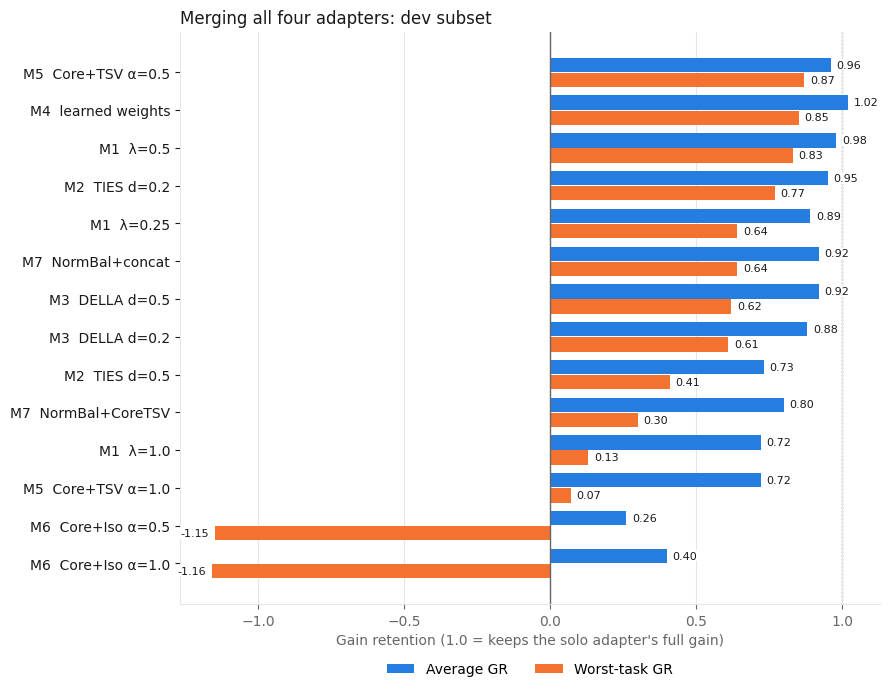

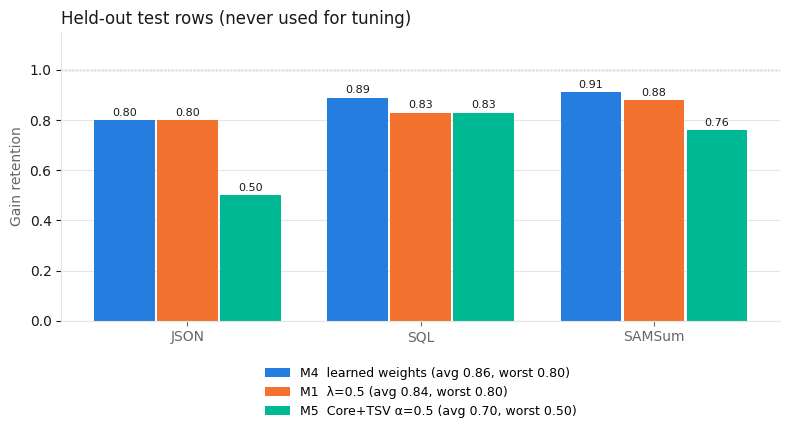

In [2]:
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA = "#257de0", "#f47230", "#00b894"      # colorblind-safe check pass
INK, INK2, GRID = "#191919", "#666666", "#e6e6e6"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False})

def label_bars(ax, bars, horizontal=False):
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.annotate(f"{v:.2f}", (v, b.get_y() + b.get_height() / 2), xytext=(4 if v >= 0 else -4, 0),
                        textcoords="offset points", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=INK,
                        bbox=dict(fc="white", ec="none", pad=0.3))
        else:
            ax.annotate(f"{v:.2f}", (b.get_x() + b.get_width() / 2, v), xytext=(0, 3 if v >= 0 else -10),
                        textcoords="offset points", ha="center", fontsize=8, color=INK)

# Chart 1: dev subset, avg vs worst GR (sabse achha worst-GR upar)
d = dev.sort_values("worst_GR")
fig, ax = plt.subplots(figsize=(9, 7))
y = range(len(d)); h = 0.38
b1 = ax.barh([i + h / 2 + 0.01 for i in y], d["avg_GR"], height=h, color=BLUE, label="Average GR")
b2 = ax.barh([i - h / 2 - 0.01 for i in y], d["worst_GR"], height=h, color=ORANGE, label="Worst-task GR")
label_bars(ax, b1, True); label_bars(ax, b2, True)
ax.set_yticks(list(y)); ax.set_yticklabels(d["method"])
ax.axvline(0, color=INK2, lw=1); ax.axvline(1, color=INK2, lw=1, ls=":", zorder=0)
ax.set_xlabel("Gain retention (1.0 = keeps the solo adapter's full gain)")
ax.set_title("Merging all four adapters: dev subset", loc="left", color=INK, fontsize=12)
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
fig.tight_layout(); fig.savefig(f"{OUT}/chart_dev_gr.png", dpi=200); plt.show()

# Chart 2: held-out, har task ka GR, 3 finalists
tasks = ["GR_json", "GR_sql", "GR_samsum"]; labels = ["JSON", "SQL", "SAMSum"]
fig, ax = plt.subplots(figsize=(8, 4.5)); w = 0.26
for j, (col, (_, r)) in enumerate(zip([BLUE, ORANGE, AQUA], hold.iterrows())):
    xs = [i + (j - 1) * (w + 0.01) for i in range(len(tasks))]
    bars = ax.bar(xs, [r[t] for t in tasks], width=w, color=col,
                  label=f"{r['method']} (avg {r['avg_GR']:.2f}, worst {r['worst_GR']:.2f})")
    label_bars(ax, bars)
ax.set_xticks(range(len(tasks))); ax.set_xticklabels(labels)
ax.axhline(1, color=INK2, lw=1, ls=":", zorder=0)
ax.set_ylim(0, 1.15); ax.set_ylabel("Gain retention")
ax.set_title("Held-out test rows (never used for tuning)", loc="left", color=INK, fontsize=12)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1, frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(f"{OUT}/chart_heldout_gr.png", dpi=200); plt.show()

In [3]:
import shutil
shutil.make_archive(OUT, "zip", OUT)
print("saved:", sorted(os.listdir(OUT)), "->", OUT + ".zip")

saved: ['chart_dev_gr.png', 'chart_heldout_gr.png', 'merge_dev_summary.csv', 'merge_heldout_summary.csv', 'merge_pair_json_tone.csv'] -> /kaggle/working/final_tables.zip
